# EDA on `img_link`

In [1]:
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# Allows for links to be displayed in full in the notebook output, rather than truncated
pd.set_option('display.max_colwidth', None)
MIN_N = 100
N = 15

# Loading Datasets

## Loading public GID data

In [ ]:
# define relevant columns to read from the CSV files
cols = ['service_request_id', 'service_request_parent_id', 'date_requested', 'case_age_days',
    'case_record_type', 'service_name', 'service_name_detail', 'date_closed', 'status', 'case_origin', 'referred', 'public_description']

# scope of data
# years = [2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]   # add earlier years
years = [2023, 2024, 2025, 2026]
base = 'https://seshat.datasd.org/get_it_done_reports/' # public src

# load dataset from urls
closed = pd.concat([pd.read_csv(f'{base}get_it_done_requests_closed_{y}_datasd.csv', usecols=cols) for y in years],
                   ignore_index=True)
open_ = pd.read_csv(f'{base}get_it_done_requests_open_datasd.csv', usecols=cols)

all_cases = pd.concat([closed, open_], ignore_index=True)
all_cases['date_closed'] = pd.to_datetime(all_cases['date_closed'])

# Keep one row per case: drop child records, then keep the earliest closure
all_cases = (all_cases[all_cases['service_request_parent_id'].isna()]
             .sort_values('date_closed')            # NaT (open) sorts last
             .drop_duplicates('service_request_id', keep='first')
             .drop(columns='service_request_parent_id'))

## Loading image data

In [3]:
img = pd.read_csv('data/public-attachments-cases.csv.gz') # image info, with link to photo when appended

## Merge datasets

In [4]:
merged_df = pd.merge(all_cases, img, left_on='service_request_id', right_on='Parent.Name', how='left')

In [5]:
# Drop unnecessary columns
merged_df = merged_df.drop(columns=["Parent.Name", "ParentId", "Name"])

# Adding URL to image
url_prefix = 'https://getitdone.sandiego.gov/servlet/servlet.FileDownload?file='
merged_df["Id"] = (url_prefix + merged_df["Id"].astype(str)).where(merged_df["Id"].notna())

# Rename column
merged_df = merged_df.rename(columns={"Id": "img_link"})

## Did the merge behave? (row inflation, match rate)

In [6]:
base_ids = all_cases['service_request_id'].nunique()
print(f'open file: {len(all_cases):,} rows, {base_ids:,} unique ids')
print(f'merged:    {len(merged_df):,} rows, {merged_df["service_request_id"].nunique():,} unique ids')
print(f'rows added by the join: {len(merged_df) - len(all_cases):,}')

# Are there ids that were already duplicated before the merge?
print(f'ids duplicated in all_cases before merge: {all_cases["service_request_id"].duplicated().sum():,}')

# Attachments whose case never appeared in the open file (closed cases, or key mismatch)
if 'Parent.Name' in img.columns:
    unmatched = ~img['Parent.Name'].isin(all_cases['service_request_id'])
    print(f'attachment rows with no case in the open file: {unmatched.mean():.1%} of {len(img):,}')
    print('key dtypes:', all_cases['service_request_id'].dtype, img['Parent.Name'].dtype)

open file: 1,445,242 rows, 1,445,242 unique ids
merged:    1,867,518 rows, 1,445,242 unique ids
rows added by the join: 422,276
ids duplicated in all_cases before merge: 0
attachment rows with no case in the open file: 52.6% of 2,588,353
key dtypes: int64 int64


In [7]:
matched = img['Parent.Name'].isin(all_cases['service_request_id'])
print(f'{matched.mean():.1%} of attachment rows now match a case')

47.4% of attachment rows now match a case


## 1. Build the case-level and image-level frames

In [8]:
# Image level: one row per attachment
images = merged_df.dropna(subset=['img_link']).copy()

# Case level: one row per case, with an image count
attr_cols = [c for c in ['service_name', 'service_name_detail', 'case_record_type', 'case_origin', 'council_district',
                         'status', 'date_requested', 'case_age_days', 'public_description', 'referred'] if c in merged_df.columns]
cases = (merged_df.groupby('service_request_id')
         .agg(**{c: (c, 'first') for c in attr_cols}, n_img=('img_link', 'count'))
         .reset_index())
cases['has_img'] = cases['n_img'] > 0
cases['date_requested'] = pd.to_datetime(cases['date_requested'], errors='coerce')

print(f'{len(cases):,} cases, {len(images):,} images')
print(f'cases with at least one image: {cases["has_img"].mean():.1%}')

1,445,242 cases, 1,226,516 images
cases with at least one image: 55.6%


## 2. How many images per case?

In [9]:
print(cases['n_img'].describe(percentiles=[.5, .9, .99]).round(2))
dist = cases['n_img'].clip(upper=5).value_counts().sort_index()
dist.index = dist.index.map(lambda v: '5+' if v == 5 else str(v))
px.bar(dist, title='Images per case (5+ pooled)', labels={'index': 'Images', 'value': 'Cases'})

count    1445242.00
mean           0.85
std            0.96
min            0.00
50%            1.00
90%            2.00
99%            3.00
max           20.00
Name: n_img, dtype: float64


In [10]:
# Cases with unusually many images (spam, bulk uploads, or a case that is really a thread)
cases.sort_values('n_img', ascending=False).head(10)[['service_request_id', 'service_name', 'n_img', 'case_origin']]

,service_request_id,service_name,n_img,case_origin
346,142322,Sidewalk Repair Issue,20,Web
2450,370499,Pavement Maintenance,17,Web
826,196351,Stormwater,16,Web
1377,260785,Sidewalk Repair Issue,16,Web
314,138032,Stormwater,14,Web
2321,355539,Pavement Maintenance,11,Web
1702,298474,Pavement Maintenance,11,Web
162,116008,Pavement Maintenance,10,Web
700,178519,Pavement Maintenance,9,Web
1227,245402,Sidewalk Repair Issue,9,Web


## 3. Link quality: duplicates and format

In [11]:
dup_links = images['img_link'].duplicated(keep=False)
print(f'image links shared by more than one row: {dup_links.sum():,}')
# Same attachment attached to several different cases?
shared = images[dup_links].groupby('img_link')['service_request_id'].nunique()
print(f'links used by more than one case: {(shared > 1).sum():,}')

print('malformed links:', (~images['img_link'].str.match(r'^https://.+file=\w+$', na=False)).sum())

# Columns that came from the attachments file (could describe type/size/owner)
extra = [c for c in merged_df.columns if c not in img.columns]
print('columns contributed by the attachments file:', extra)

image links shared by more than one row: 0
links used by more than one case: 0


malformed links: 0
columns contributed by the attachments file: ['service_request_id', 'date_requested', 'case_age_days', 'case_record_type', 'service_name', 'service_name_detail', 'date_closed', 'status', 'case_origin', 'referred', 'public_description', 'img_link']


In [12]:
# File type: you dropped `Name`, but the extension tells you image vs pdf vs video. Re-derive it from `img`
if 'Name' in img.columns:
    ext = img['Name'].str.extract(r'\.([A-Za-z0-9]+)$')[0].str.lower()
    print(ext.value_counts(dropna=False).head(15))

0
jpg     2314215
jpeg     245244
png       28511
gif         149
pdf         130
bmp          59
docx         20
csv           9
xlsx          7
mov           5
heic          2
NaN           1
doc           1
Name: count, dtype: int64


# Weird File Types

In [13]:
# Extension per attachment, keyed by attachment Id
img['ext'] = img['Name'].str.extract(r'\.([A-Za-z0-9]+)$')[0].str.lower()
ext_by_id = img.drop_duplicates('Id').set_index('Id')['ext']

# Pull the Id back out of the URL and attach the extension to merged_df
merged_df['att_id'] = merged_df['img_link'].str.extract(r'file=(\w+)$')[0]
merged_df['ext'] = merged_df['att_id'].map(ext_by_id)

weird_ext = ['docx', 'doc', 'csv', 'xlsx', 'xls']
weird_rows = merged_df[merged_df['ext'].isin(weird_ext)]

print(f"{len(weird_rows):,} attachment rows on {weird_rows['service_request_id'].nunique():,} cases")

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 80)
weird_rows.sort_values('ext').groupby('ext').head(5)

35 attachment rows on 29 cases


,service_request_id,date_requested,case_age_days,case_record_type,service_name,service_name_detail,date_closed,status,case_origin,referred,public_description,img_link,att_id,ext
289792,4233289,2023-05-11 12:41:00.000,102,DSD,STRO Violation,NaN,2023-08-21,Closed,Web,NaN,3715 10TH AVEUsing same license STR-03375L for 8 separate units.airbnb.com/r...,https://getitdone.sandiego.gov/servlet/servlet.FileDownload?file=00P8z000002...,00P8z000002jj7lEAA,csv
826547,4853568,2024-07-24 09:49:00.000,81,DSD,STRO Violation,NaN,2024-10-13,Closed,Web,NaN,Hello - The STRO at 1251 Parker Place #1B has an active code violation case ...,https://getitdone.sandiego.gov/servlet/servlet.FileDownload?file=00Pcs000001...,00Pcs000001OZovEAG,csv
950287,4285600,2023-06-17 09:18:00.000,589,DSD,STRO Violation,NaN,2025-01-26,Closed,Web,NaN,1868 Bacon st. Not exempt property. airbnb.com/rooms/868998595622762714. Sam...,https://getitdone.sandiego.gov/servlet/servlet.FileDownload?file=00P8z000002...,00P8z000002r0i5EAA,csv
213036,4285585,2023-06-17 09:11:00.000,3,DSD,STRO Violation,NaN,2023-06-20,Closed,Web,NaN,"511 F St. ""Chris & Meghan"" All 17 listings claiming exempt. They look like f...",https://getitdone.sandiego.gov/servlet/servlet.FileDownload?file=00P8z000002...,00P8z000002r0i1EAA,csv
213037,4285585,2023-06-17 09:11:00.000,3,DSD,STRO Violation,NaN,2023-06-20,Closed,Web,NaN,"511 F St. ""Chris & Meghan"" All 17 listings claiming exempt. They look like f...",https://getitdone.sandiego.gov/servlet/servlet.FileDownload?file=00P8z000002...,00P8z000002r0i0EAA,csv
1115430,5251138,2025-06-10 16:00:00.000,1,DSD,STRO Violation,NaN,2025-06-11,Closed,Web,NaN,on 6/9/2025 in response to renters talking loudly enough to wake me up with ...,https://getitdone.sandiego.gov/servlet/servlet.FileDownload?file=00Pcs00000m...,00Pcs00000mnwwvEAA,doc
1117477,5102780,2025-02-07 23:14:00.000,125,DSD,STRO Violation,NaN,2025-06-12,Closed,Web,NaN,"There are 4 STR units illegally being operated at 3609 Keating St 92110, and...",https://getitdone.sandiego.gov/servlet/servlet.FileDownload?file=00Pcs00000V...,00Pcs00000V0K1lEAF,docx
140545,4211704,2023-04-27 04:18:00.000,0,DSD,STRO Violation,NaN,2023-04-27,Closed,Web,NaN,Testing by panda Do not enforce.,https://getitdone.sandiego.gov/servlet/servlet.FileDownload?file=00P8z000002...,00P8z000002gQq8EAE,docx
1805848,5834631,2026-08-01 20:43:02.000,95,DSD,STRO Violation,NaN,NaT,In Process,Web,NaN,AirBnB guests were blocking my driveway with a car and trash cans. They move...,https://getitdone.sandiego.gov/servlet/servlet.FileDownload?file=00Pcs00001p...,00Pcs00001pOPc8EAG,docx
1824613,5696009,2026-04-28 16:12:13.000,190,DSD,Building and Land Use Enforcement,NaN,NaT,New,Web,NaN,"The owner, appears to have vacated the property and converted what was once ...",https://getitdone.sandiego.gov/servlet/servlet.FileDownload?file=00Pcs00001Z...,00Pcs00001ZYvSHEA1,docx


In [14]:
weird_rows['img_link'].head()

140545    https://getitdone.sandiego.gov/servlet/servlet.FileDownload?file=00P8z000002...
156471    https://getitdone.sandiego.gov/servlet/servlet.FileDownload?file=00P8z000002...
168143    https://getitdone.sandiego.gov/servlet/servlet.FileDownload?file=00P8z000002...
199567    https://getitdone.sandiego.gov/servlet/servlet.FileDownload?file=00P8z000002...
205363    https://getitdone.sandiego.gov/servlet/servlet.FileDownload?file=00P8z000002...
Name: img_link, dtype: object

## 4. Who uploads images?

In [15]:
def coverage(col, min_n=MIN_N, top=N):
    g = cases.groupby(col, observed=True)['has_img'].agg(n='size', pct_with_img=lambda s: s.mean() * 100)
    return g[g['n'] >= min_n].sort_values('pct_with_img', ascending=False).round(1).head(top)

for col in ['case_origin', 'case_record_type', 'council_district']:
    if col in cases.columns:
        print(f'--- {col}')
        display(coverage(col))

--- case_origin


,n,pct_with_img
case_origin,,
Mobile,741472,82.2
Web,324257,60.0
Email,3349,0.1
Worker App,197114,0.1
CC Self Generate,12798,0.1
Internal,2276,0.0
Phone,109185,0.0
Crew/Self Generated,47202,0.0
Construction Patrol,415,0.0


--- case_record_type


,n,pct_with_img
case_record_type,,
Parking,247184,92.6
TSW ROW,40143,87.2
Neighborhood Policing,133543,72.1
ESD Abatement,385,69.4
Parks & Recreation,41528,68.0
TSW,420330,58.0
Traffic Engineering,12212,55.3
DSD,16917,50.6
Storm Water Code Enforcement,10615,47.7


In [16]:
cov = coverage('service_name', top=40).sort_values('pct_with_img')
px.bar(cov, x='pct_with_img', y=cov.index, orientation='h',
       title='% of cases with an image, by service (n >= 100)', labels={'pct_with_img': '% with image', 'y': ''})

In [17]:
cases['month'] = cases['date_requested'].dt.to_period('M').dt.to_timestamp()
trend = cases.groupby('month')['has_img'].agg(n='size', pct=lambda s: s.mean() * 100).reset_index()
px.line(trend[trend['n'] >= 50], x='month', y='pct', title='% of cases with an image, by month requested')

## 5. Do cases with images differ?

In [18]:
cmp = cases.groupby('has_img').agg(
    n=('has_img', 'size'),
    pct_other=('service_name', lambda s: (s == 'Other').mean() * 100),
    pct_with_description=('public_description', lambda s: s.notna().mean() * 100),
    pct_referred=('referred', lambda s: s.notna().mean() * 100),
    median_age_days=('case_age_days', 'median'),
).round(1)
cmp

,n,pct_other,pct_with_description,pct_referred,median_age_days
has_img,,,,,
False,641002,2.2,56.8,4.3,1.0
True,804240,3.1,99.9,10.1,5.0


## 6. Is there enough image data per category for a classifier?
Counts cases with at least one image per service. Splitting by origin shows whether the images mostly come from the app (user photos) or from staff.

In [19]:
imgd = cases[cases['has_img']]
by_svc = imgd.groupby('service_name').agg(cases_with_img=('has_img', 'size'), total_images=('n_img', 'sum')).sort_values('cases_with_img', ascending=False)
for t in (100, 500, 1000):
    print(f'services with >= {t} imaged cases: {(by_svc["cases_with_img"] >= t).sum()}')
print(f'top 10 services hold {by_svc["cases_with_img"].head(10).sum() / by_svc["cases_with_img"].sum():.1%} of imaged cases')
by_svc.head(N)

services with >= 100 imaged cases: 38
services with >= 500 imaged cases: 36
services with >= 1000 imaged cases: 35
top 10 services hold 72.5% of imaged cases


,cases_with_img,total_images
service_name,,
Parking Violation,161581,255783
Encampment,100127,160535
Illegal Dumping,67003,94200
Graffiti - Public,57803,74317
Parking - 72-Hours,47034,76307
Graffiti - Code Enforcement,39713,52341
Missed Collection,35641,45484
Pothole,25644,44412
Other,24828,40357


In [20]:
px.bar(by_svc.head(N).sort_values('cases_with_img'), x='cases_with_img', y=by_svc.head(N).sort_values('cases_with_img').index,
       orientation='h', title=f'Imaged cases per service (top {N})', labels={'y': '', 'x': 'Cases with image'})

In [21]:
# 'Other' with images: how much of the vague category could be examined visually?
oth = cases[cases['service_name'] == 'Other']
print(f"'Other': {len(oth):,} cases, {oth['has_img'].mean():.1%} with an image, {oth['n_img'].sum():,} images in total")

'Other': 38,944 cases, 63.8% with an image, 40,357 images in total


## 7. Do the links actually load?
Samples a few hundred links. A 200 can still be a login page, so it also checks that the content type is an image.
Run on a small sample, and respect the site's rate limits.

In [22]:
import requests
from concurrent.futures import ThreadPoolExecutor

SAMPLE = 200
sample_links = images['img_link'].drop_duplicates().sample(min(SAMPLE, images['img_link'].nunique()), random_state=0)

def check(url):
    try:
        r = requests.get(url, stream=True, timeout=10, allow_redirects=True)
        out = {'url': url, 'status': r.status_code, 'content_type': r.headers.get('Content-Type', ''),
               'bytes': int(r.headers.get('Content-Length', 0) or 0), 'final_url': r.url}
        r.close()
        return out
    except Exception as e:
        return {'url': url, 'status': None, 'content_type': type(e).__name__, 'bytes': 0, 'final_url': ''}

with ThreadPoolExecutor(max_workers=4) as ex:
    results = pd.DataFrame(list(ex.map(check, sample_links)))

results['is_image'] = results['content_type'].str.lower().str.startswith('image/')
print(results['status'].value_counts(dropna=False))
print(results['content_type'].str.split(';').str[0].value_counts().head(10))
print(f"{results['is_image'].mean():.1%} of sampled links returned an image")
results[~results['is_image']].head(10)

status
200    200
Name: count, dtype: int64
content_type
image/jpeg    200
Name: count, dtype: int64
100.0% of sampled links returned an image


,url,status,content_type,bytes,final_url,is_image


# Photo Availability 

In [23]:
import io
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import plotly.express as px
import requests
import matplotlib.pyplot as plt
from PIL import Image
from plotly.subplots import make_subplots
from scipy.stats import spearmanr

MIN = 100
M = 10

In [24]:
n_img = merged_df.groupby('service_request_id')['img_link'].count().rename('n_img')
cases = (merged_df.drop_duplicates('service_request_id')
         .drop(columns=['img_link'], errors='ignore')
         .join(n_img, on='service_request_id'))
cases['date_requested'] = pd.to_datetime(cases['date_requested'], errors='coerce')
cases['date_closed'] = pd.to_datetime(cases['date_closed'], errors='coerce')
cases['service_name'] = cases['service_name'].fillna('Unknown')
cases['case_record_type'] = cases['case_record_type'].fillna('Unknown')
cases['has_img'] = cases['n_img'] > 0

# "Open" = no close date. Backlog = open for more than a year as of today.
SNAPSHOT = pd.Timestamp.today().normalize()
cases['is_open'] = cases['date_closed'].isna()
cases['age_days'] = (SNAPSHOT - cases['date_requested'].dt.normalize()).dt.days.where(cases['is_open'])
cases['open_over_1yr'] = cases['is_open'] & (cases['age_days'] > 365)

print(f'{len(cases):,} cases; {cases["has_img"].mean():.1%} have a photo; '
      f'{cases["is_open"].sum():,} open; {cases["open_over_1yr"].sum():,} open > 1 year')
print('Status of cases with no close date (check these really are open):')
print(cases.loc[cases['is_open'], 'status'].value_counts().head(6))

1,445,242 cases; 55.6% have a photo; 62,589 open; 30,406 open > 1 year
Status of cases with no close date (check these really are open):
status
In Process    52182
New           10407
Name: count, dtype: int64


In [25]:
svc = cases.groupby('service_name').agg(
    n=('has_img', 'size'),
    imaged=('has_img', 'sum'),
    pct_with_photo=('has_img', lambda s: s.mean() * 100),
    open_over_1yr=('open_over_1yr', 'sum'))
svc['backlog_rate'] = svc['open_over_1yr'] / svc['n'] * 100
svc = svc[svc['n'] >= MIN]


vol = svc.sort_values('n', ascending=False).head(N).sort_values('n')
vol = vol.reset_index()

fig = px.bar(
    vol,
    x='n',
    y='service_name',
    orientation='h',
    title=f'Top {M} categories by volume and photo availability',
    hover_data={
        'n': ':,',
        'imaged': ':,',
        'pct_with_photo': ':.1f'
    },
    labels={
        'n': 'Number of Cases',
        'service_name': '',
        'imaged': 'Cases with Photos',
        'pct_with_photo': '% with Photo'
    }
)

# Background bar: total cases
fig.update_traces(
    marker_color='lightgray',
    name='Total Cases'
)

# Foreground bar: cases with photos
fig.add_bar(
    x=vol['imaged'],
    y=vol['service_name'],
    orientation='h',
    name='Cases with Photos',
    marker_color='seagreen',
    text=vol['pct_with_photo'].apply(lambda x: f'{x:.1f}%'),
    textposition='inside',
    insidetextanchor='middle',
    customdata=vol[['pct_with_photo']],
    hovertemplate=(
        'Category: %{y}<br>'
        'Cases with Photos: %{x:,}<br>'
        'Photo Availability: %{customdata[0]:.1f}%'
        '<extra></extra>'
    )
)

fig.update_layout(
    height=520,
    barmode='overlay',
    xaxis_title='Number of Cases',
    legend_title='',
    legend=dict(x=0.7, y=1.1, orientation='h')
)

fig.show()

# Where is the backlog, and are those the categories with photos?

In [26]:
t = svc.sort_values('open_over_1yr', ascending=False).head(M).sort_values('open_over_1yr')
fig = make_subplots(rows=1, cols=2, shared_yaxes=True, horizontal_spacing=0.04,
                    subplot_titles=('Open for more than a year', 'Cases with a photo'))
fig.add_bar(y=t.index, x=t['open_over_1yr'], orientation='h', marker_color='#d62728', row=1, col=1,
            hovertemplate='%{y}: %{x:,} open > 1yr<extra></extra>')
fig.add_bar(y=t.index, x=t['imaged'], orientation='h', marker_color='#2ca02c', row=1, col=2,
            text=t['pct_with_photo'].map('{:.0f}% of cases'.format), textposition='auto',
            hovertemplate='%{y}: %{x:,} cases with a photo<extra></extra>')
fig.update_layout(title=f'The {M} categories with the biggest backlog, and how many photos each has',
                  showlegend=False, height=560)
fig.show()

# What do photos actually show?

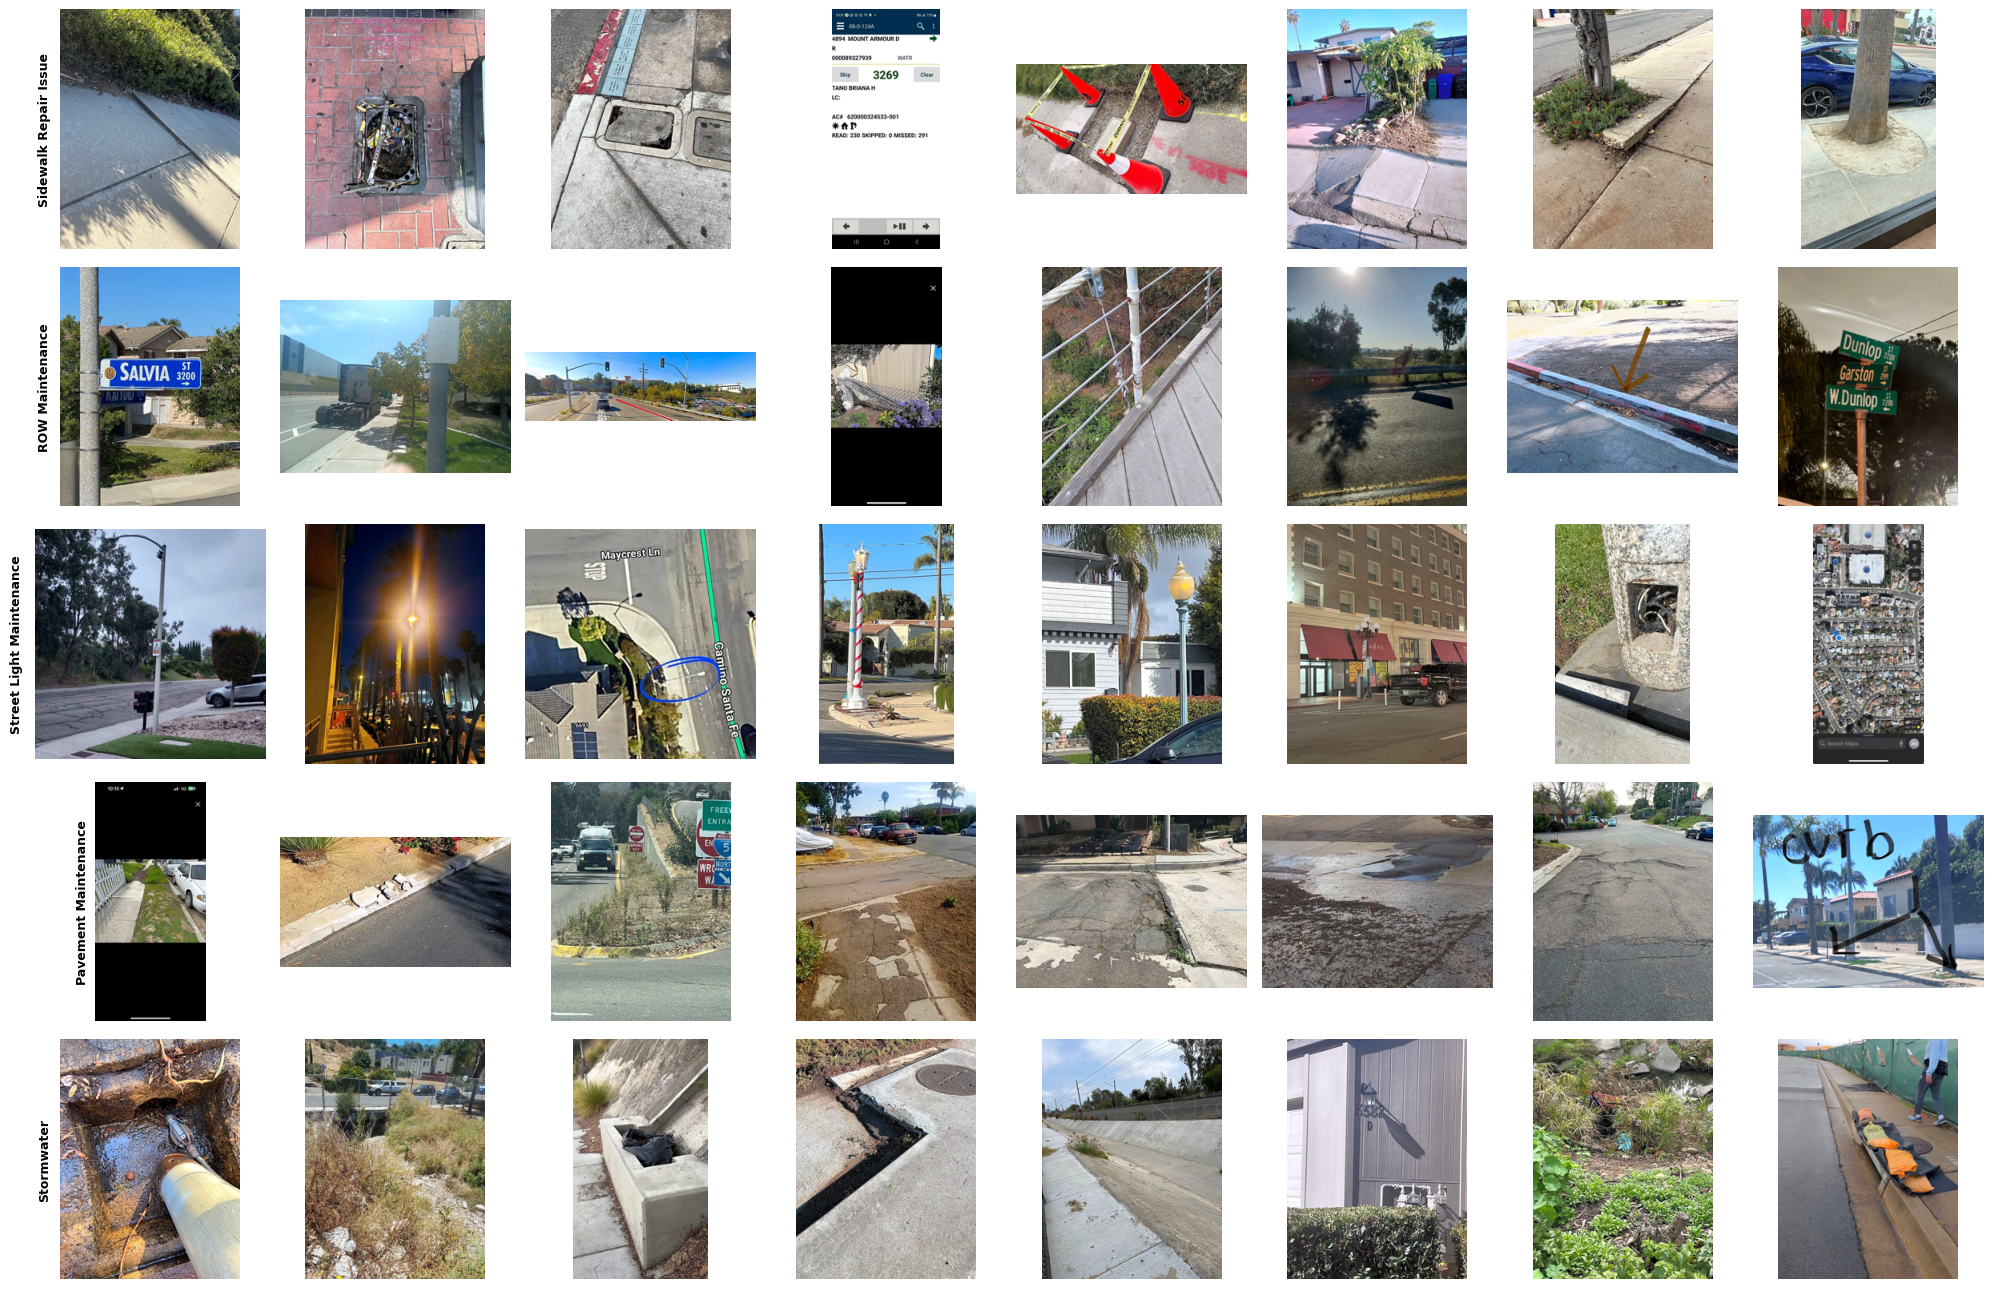

In [ ]:
first_img = (merged_df.dropna(subset=['img_link']).drop_duplicates('service_request_id')
             [['service_request_id', 'img_link', 'service_name']])

def fetch_image(url, size=(300, 300)):
    try:
        r = requests.get(url, timeout=10)
        r.raise_for_status()
        im = Image.open(io.BytesIO(r.content)).convert('RGB')
        im.thumbnail(size)
        return im
    except Exception:
        return None

def category_sheet(categories, k=8, seed=21): # change seed for different random samples
    picks = []
    for c in categories:
        pool = first_img[first_img['service_name'] == c]
        picks.append(pool.sample(min(k, len(pool)), random_state=seed)['img_link'].tolist())
    with ThreadPoolExecutor(max_workers=4) as ex:
        loaded = [list(ex.map(fetch_image, urls)) for urls in picks]
    fig, axes = plt.subplots(len(categories), k, figsize=(2.5 * k, 2.6 * len(categories)), squeeze=False)
    for i, c in enumerate(categories):
        for j in range(k):
            ax = axes[i, j]
            ax.axis('off')
            if j < len(loaded[i]) and loaded[i][j] is not None:
                ax.imshow(loaded[i][j])
        axes[i, 0].text(-0.05, 0.5, c[:28], transform=axes[i, 0].transAxes, rotation=90, va='center', ha='right', fontsize=9, weight='bold')
    plt.tight_layout()
    plt.show()

# Top categories by backlog that also have enough photos to sample
cands = svc[svc['imaged'] >= 6].sort_values('open_over_1yr', ascending=False).head(5).index.tolist()
category_sheet(cands)